In [2]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [3]:

import zipfile
import os

zip_path = "/content/drive/MyDrive/household.zip"
extract_path = "/content/electricity_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIP extracted successfully!")

# Find the dataset file
file_path = None

for root, dirs, files in os.walk(extract_path):
    if "household_power_consumption.txt" in files:
        file_path = os.path.join(
            root, "household_power_consumption.txt"
        )
        break

print("Dataset path:", file_path)
print("Dataset found:", file_path is not None)


ZIP extracted successfully!
Dataset path: /content/electricity_data/household_power_consumption.txt
Dataset found: True


In [4]:

import pandas as pd

df = pd.read_csv(
    file_path,
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [5]:

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check missing values in each column
print("\nMissing values:")
print(df.isna().sum())

# Check dataset information
print("\nDataset information:")
df.info()


Duplicate rows: 0

Missing values:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB


In [6]:

import pandas as pd
import numpy as np

# Numerical columns
features = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

# Convert Date and Time into a timestamp
df["Timestamp"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

# Ensure numerical columns have numeric values
for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Sort records by timestamp
df = df.dropna(subset=["Timestamp"])
df = df.sort_values("Timestamp")
df = df.drop_duplicates(subset=["Timestamp"])
df = df.set_index("Timestamp")

# Fill only short internal gaps
df[features] = df[features].interpolate(
    method="time",
    limit=5,
    limit_area="inside"
)

# Check remaining missing values
print("Missing values after interpolation:")
print(df[features].isna().sum())

print("\nDataset shape after cleaning:")
print(df.shape)


Missing values after interpolation:
Global_active_power      25823
Global_reactive_power    25823
Voltage                  25823
Global_intensity         25823
Sub_metering_1           25823
Sub_metering_2           25823
Sub_metering_3           25823
dtype: int64

Dataset shape after cleaning:
(2075259, 9)


In [7]:

# Check which rows have complete numerical values
valid_rows = df[features].notna().all(axis=1)

# Check whether consecutive timestamps are exactly one minute apart
one_minute_gap = df.index.to_series().diff().eq(
    pd.Timedelta(minutes=1)
)

# A valid record must have all numerical values
# and must follow a valid record exactly one minute earlier
consecutive_valid = valid_rows & one_minute_gap

# Find a continuous run of valid records
run_id = (
    consecutive_valid.ne(consecutive_valid.shift())
    .cumsum()
)

# Count records in each run
run_lengths = consecutive_valid.groupby(run_id).sum()

# Find a run containing at least 10,000 records
eligible_runs = run_lengths[run_lengths >= 9999]

print("Longest valid run:", int(run_lengths.max()))

if len(eligible_runs) == 0:
    print("No suitable run found. We will use an alternative cleaning method.")
else:
    selected_run_id = eligible_runs.index[0]

    # Include the first valid record before the run
    run_positions = np.flatnonzero(
        (run_id == selected_run_id).to_numpy()
    )

    start_pos = run_positions[0] - 1
    end_pos = start_pos + 10000

    selected_data = df.iloc[start_pos:end_pos][features].copy()

    # Verify the selected records
    print("Selected dataset shape:", selected_data.shape)
    print("Missing values:", selected_data.isna().sum().sum())
    print("First timestamp:", selected_data.index[0])
    print("Last timestamp:", selected_data.index[-1])
    print("All timestamps consecutive:",
          selected_data.index.to_series().diff().iloc[1:].eq(
              pd.Timedelta(minutes=1)
          ).all())


Longest valid run: 649560
Selected dataset shape: (10000, 7)
Missing values: 0
First timestamp: 2006-12-16 17:24:00
Last timestamp: 2006-12-23 16:03:00
All timestamps consecutive: True


In [8]:

from sklearn.preprocessing import MinMaxScaler

# Target: predict Global_active_power
target = "Global_active_power"

# Number of previous minutes used for prediction
LOOKBACK = 60

# Split chronologically: 70% train, 15% validation, 15% test
n = len(selected_data)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Fit scalers using training data only
feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

feature_scaler.fit(selected_data[features].iloc[:train_end])
target_scaler.fit(selected_data[[target]].iloc[:train_end])

# Normalize all selected records
X_scaled = feature_scaler.transform(selected_data[features])
y_scaled = target_scaler.transform(
    selected_data[[target]]
).ravel()

# Create sequences: previous 60 minutes -> next minute
X, y, target_indices = [], [], []

for i in range(LOOKBACK, n):
    X.append(X_scaled[i - LOOKBACK:i])
    y.append(y_scaled[i])
    target_indices.append(i)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)
target_indices = np.array(target_indices)

# Split sequences based on the timestamp of the target
train_mask = target_indices < train_end
val_mask = (
    (target_indices >= train_end) &
    (target_indices < val_end)
)
test_mask = target_indices >= val_end

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Training input:", X_train.shape)
print("Training target:", y_train.shape)
print("Validation input:", X_val.shape)
print("Validation target:", y_val.shape)
print("Testing input:", X_test.shape)
print("Testing target:", y_test.shape)
print("Missing values in selected data:",
      selected_data[features].isna().sum().sum())


Training input: (6940, 60, 7)
Training target: (6940,)
Validation input: (1500, 60, 7)
Validation target: (1500,)
Testing input: (1500, 60, 7)
Testing target: (1500,)
Missing values in selected data: 0


In [9]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Make results more reproducible
tf.random.set_seed(42)
np.random.seed(42)

# Build the LSTM model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(60, 7)),

    tf.keras.layers.LSTM(64),

    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(16, activation="relu"),

    tf.keras.layers.Dense(1)
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Display model architecture
model.summary()

# Stop training if validation loss does not improve
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,489 (76.13 KB)

 Trainable params: 19,489 (76.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - loss: 0.0198 - mae: 0.0931 - val_loss: 0.0047 - val_mae: 0.0391
Epoch 2/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - loss: 0.0075 - mae: 0.0606 - val_loss: 0.0036 - val_mae: 0.0354
Epoch 3/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - loss: 0.0054 - mae: 0.0484 - val_loss: 0.0031 - val_mae: 0.0315
Epoch 4/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - loss: 0.0048 - mae: 0.0442 - val_loss: 0.0030 - val_mae: 0.0308
Epoch 5/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - loss: 0.0046 - mae: 0.0430 - val_loss: 0.0029 - val_mae: 0.0313
Epoch 6/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - loss: 0.0044 - mae: 0.0416 - val_loss: 0.0028 - val_mae: 0.0304
Epoch 7/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - loss: 0.0044 - mae: 0.0416 - val_loss: 0.0025 - val_mae: 0.0264
Epoch 8/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - loss: 0.0042 - mae: 0.0394 - val_loss: 0.0024 - val_mae: 0.0250
Epoch 9/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/

In [10]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict electricity consumption for unseen test sequences
pred_scaled = model.predict(X_test, verbose=0)

# Convert normalized values back to kW
actual = target_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

predicted = target_scaler.inverse_transform(
    pred_scaled
).ravel()

# Evaluation metrics
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print(f"Test MAE:  {mae:.4f} kW")
print(f"Test RMSE: {rmse:.4f} kW")


Test MAE:  0.5268 kW
Test RMSE: 0.7077 kW


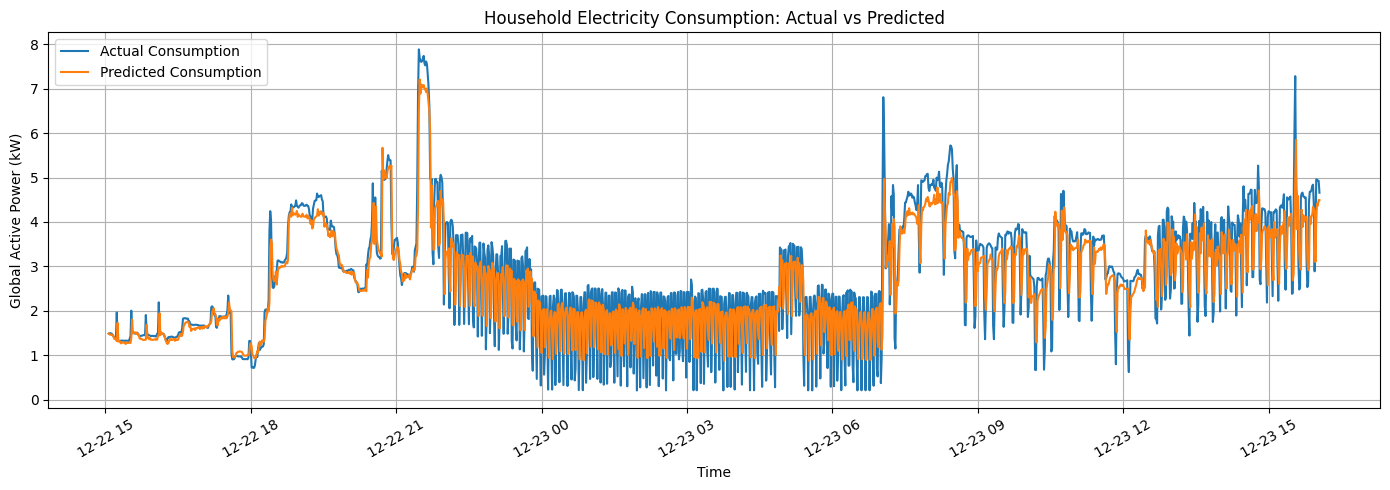

In [11]:

import matplotlib.pyplot as plt

test_times = selected_data.index[target_indices[test_mask]]

plt.figure(figsize=(14, 5))
plt.plot(test_times, actual, label="Actual Consumption")
plt.plot(test_times, predicted, label="Predicted Consumption")

plt.title("Household Electricity Consumption: Actual vs Predicted")
plt.xlabel("Time")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.xticks(rotation=30)
plt.grid(True)
plt.tight_layout()
plt.show()


In [14]:

# Use the last 60 available records as input
last_60 = selected_data[features].iloc[-60:]

# Normalize using the same scaler used during training
input_scaled = feature_scaler.transform(last_60)

# Shape: (1 sample, 60 minutes, 7 features)
input_array = input_scaled.reshape(1, 60, 7)

# Predict the next minute
pred_scaled = model.predict(input_array, verbose=0)

# Convert prediction back to kW
next_prediction = target_scaler.inverse_transform(
    pred_scaled
)[0, 0]

last_time = selected_data.index[-1]
next_time = last_time + pd.Timedelta(minutes=1)

print("Last available timestamp:", last_time)
print("Forecast timestamp:", next_time)
print(f"Predicted electricity consumption: {next_prediction:.3f} kW")


Last available timestamp: 2006-12-23 16:03:00
Forecast timestamp: 2006-12-23 16:04:00
Predicted electricity consumption: 4.299 kW


In [15]:
check_time = pd.Timestamp("2006-12-23 16:04:00")

if check_time in df.index:
    print("Actual value:", df.loc[check_time, "Global_active_power"])
else:
    print("Timestamp not found in df index")

Actual value: 2.87


In [16]:
from google.colab import drive
import os
import pandas as pd

drive.mount('/content/drive')

save_folder = "/content/drive/MyDrive/Household_Electricity_Project"
os.makedirs(save_folder, exist_ok=True)

# Save trained LSTM model
model.save(
    os.path.join(save_folder, "household_electricity_lstm.keras")
)

# Save actual and predicted test results
results = pd.DataFrame({
    "Timestamp": test_times,
    "Actual_Consumption_kW": actual,
    "Predicted_Consumption_kW": predicted
})

results.to_csv(
    os.path.join(save_folder, "electricity_predictions.csv"),
    index=False
)

print("Model and results saved successfully!")
print("Saved folder:", save_folder)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model and results saved successfully!
Saved folder: /content/drive/MyDrive/Household_Electricity_Project
